# Assessment Lab 1 - 24.7.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    1. Use the KNN classifier model to classify the raisin categories based on the
       input features given in the raisin dataset. Find the suitable k value for
       the dataset. Use the split of 80 and 20 for training and testing the
       dataset. Analyze the performance and visualize the results.

    2. Generate the model to classify the churn using Categorical Naive Bayes
       classifier for the given dataset “churn.csv”. Use the following input
       features - 'Contract', 'PaymentMethod', 'InternetService',
       'OnlineSecurity', 'TechSupport', 'StreamingTV', 'MonthlyCharges' and
       target feature as “churn”. Use the split of 70 and 30 for training and
       testing the dataset. Compare the performance of the models and visualize
       the results.

### 1.

### KNN - Raisin classification

#### Load dataset

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [42]:
raisin_df = pd.read_csv('Lab 3-24.7.26/Raisin.csv')
raisin_df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [43]:
raisin_df['Class'].value_counts()

Class
Kecimen    450
Besni      450
Name: count, dtype: int64

#### Features & target

In [44]:
X_raisin = raisin_df.drop(columns='Class')
y_raisin = raisin_df['Class']

#### Train-test split

In [45]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_raisin, y_raisin, test_size=0.2, random_state=1265, stratify=y_raisin
)

#### Feature scaling

In [46]:
scaler = StandardScaler()
X_train_r_scaled = scaler.fit_transform(X_train_r)
X_test_r_scaled = scaler.transform(X_test_r)

#### Find suitable k

Best k: 11, CV Accuracy: 0.8639


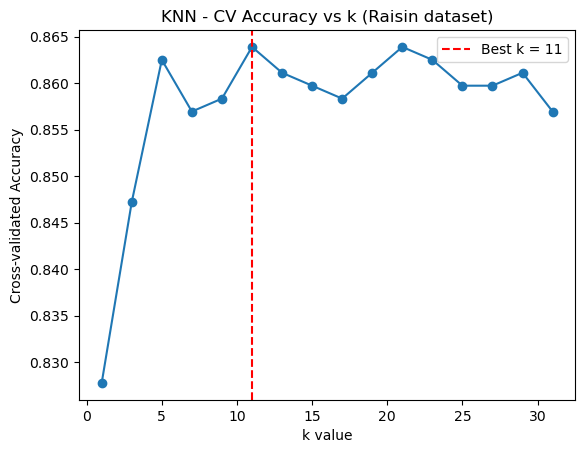

In [47]:
k_values = range(1, 32, 2)
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_r_scaled, y_train_r, cv=5)
    cv_scores.append(scores.mean())

best_k = k_values[np.argmax(cv_scores)]
print(f"Best k: {best_k}, CV Accuracy: {max(cv_scores):.4f}")

plt.plot(k_values, cv_scores, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k = {best_k}')
plt.xlabel('k value')
plt.ylabel('Cross-validated Accuracy')
plt.title('KNN - CV Accuracy vs k (Raisin dataset)')
plt.legend()
plt.show()

#### Train final model

In [48]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_r_scaled, y_train_r)

y_pred_r = knn_model.predict(X_test_r_scaled)

#### Performance evaluation

In [49]:
knn_accuracy = accuracy_score(y_test_r, y_pred_r)
print(f"Accuracy: {knn_accuracy:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test_r, y_pred_r))

Accuracy: 0.8444

Classification Report:
              precision    recall  f1-score   support

       Besni       0.85      0.83      0.84        90
     Kecimen       0.84      0.86      0.85        90

    accuracy                           0.84       180
   macro avg       0.84      0.84      0.84       180
weighted avg       0.84      0.84      0.84       180



#### Visualize results

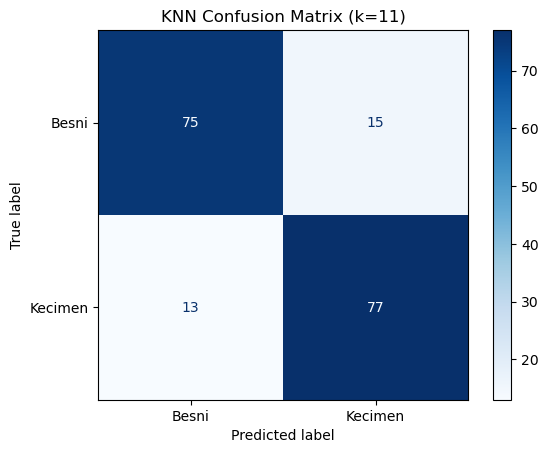

In [50]:
cm_r = confusion_matrix(y_test_r, y_pred_r, labels=knn_model.classes_)
disp_r = ConfusionMatrixDisplay(confusion_matrix=cm_r, display_labels=knn_model.classes_)
disp_r.plot(cmap='Blues')
plt.title(f'KNN Confusion Matrix (k={best_k})')
plt.show()

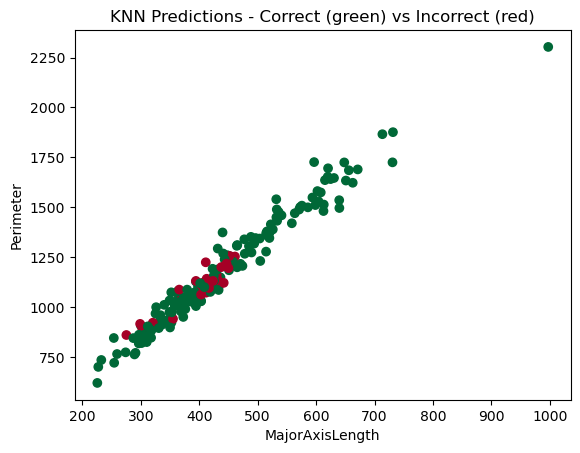

In [51]:
plt.scatter(X_test_r['MajorAxisLength'], X_test_r['Perimeter'], c=(y_test_r == y_pred_r), cmap='RdYlGn')
plt.xlabel('MajorAxisLength')
plt.ylabel('Perimeter')
plt.title('KNN Predictions - Correct (green) vs Incorrect (red)')
plt.show()

### 2.

### Categorical Naive Bayes - Churn classification

#### Load dataset

In [52]:
churn_df = pd.read_csv('Lab 3-24.7.26/churn.csv')
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### Select features

In [53]:
features = ['Contract', 'PaymentMethod', 'InternetService', 'OnlineSecurity',
            'TechSupport', 'StreamingTV', 'MonthlyCharges']

churn_sub = churn_df[features + ['Churn']].copy()
churn_sub.head()

,Contract,PaymentMethod,InternetService,OnlineSecurity,TechSupport,StreamingTV,MonthlyCharges,Churn
0,Month-to-month,Electronic check,DSL,No,No,No,29.85,No
1,One year,Mailed check,DSL,Yes,No,No,56.95,No
2,Month-to-month,Mailed check,DSL,Yes,No,No,53.85,Yes
3,One year,Bank transfer (automatic),DSL,Yes,Yes,No,42.30,No
4,Month-to-month,Electronic check,Fiber optic,No,No,No,70.70,Yes


#### Train-test split

In [54]:
X_churn = churn_sub[features]
y_churn = churn_sub['Churn']

X_train_c_raw, X_test_c_raw, y_train_c, y_test_c = train_test_split(
    X_churn, y_churn, test_size=0.3, random_state=1265, stratify=y_churn
)

#### Preprocessing (fit on training data only)

The `MonthlyCharges` bin edges and the ordinal encoder's category mapping are
both learned from `X_train_c_raw` only, then applied unchanged to the test set.
Fitting them on the full dataset before splitting would let the test set's
distribution leak into training (the qcut bin edges, in particular, would shift
to reflect test rows), inflating the reported accuracy relative to what the
model would see on genuinely unseen data.

In [55]:
X_train_c_raw = X_train_c_raw.copy()
X_test_c_raw = X_test_c_raw.copy()

# Bin MonthlyCharges using quantile edges learned from the training set only
_, bin_edges = pd.qcut(X_train_c_raw['MonthlyCharges'], q=4, retbins=True)
bin_edges[0], bin_edges[-1] = -np.inf, np.inf
bin_labels = ['Low', 'Medium', 'High', 'Very High']

X_train_c_raw['MonthlyCharges'] = pd.cut(X_train_c_raw['MonthlyCharges'], bins=bin_edges, labels=bin_labels)
X_test_c_raw['MonthlyCharges'] = pd.cut(X_test_c_raw['MonthlyCharges'], bins=bin_edges, labels=bin_labels)

# Fit the encoder on the training set only, then apply it to both splits
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_c = encoder.fit_transform(X_train_c_raw)
X_test_c = encoder.transform(X_test_c_raw)

#### Train model

In [56]:
nb_model = CategoricalNB()
nb_model.fit(X_train_c, y_train_c)

y_pred_c = nb_model.predict(X_test_c)

#### Performance evaluation

In [57]:
nb_accuracy = accuracy_score(y_test_c, y_pred_c)
print(f"Accuracy: {nb_accuracy:.4f}")
print()
print("Classification Report:")
print(classification_report(y_test_c, y_pred_c))

Accuracy: 0.7269

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.71      0.79      1552
         Yes       0.49      0.77      0.60       561

    accuracy                           0.73      2113
   macro avg       0.69      0.74      0.70      2113
weighted avg       0.79      0.73      0.74      2113



#### Visualize results

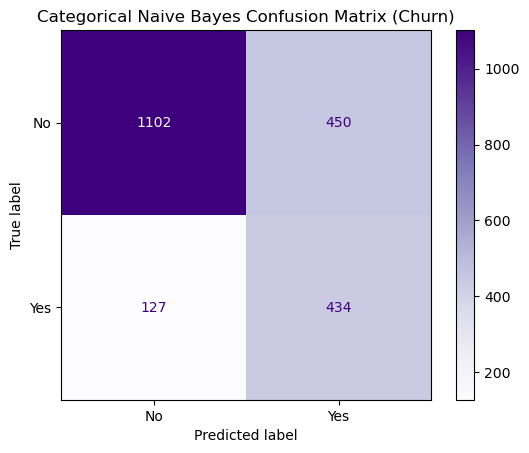

In [58]:
cm_c = confusion_matrix(y_test_c, y_pred_c, labels=nb_model.classes_)
disp_c = ConfusionMatrixDisplay(confusion_matrix=cm_c, display_labels=nb_model.classes_)
disp_c.plot(cmap='Purples')
plt.title('Categorical Naive Bayes Confusion Matrix (Churn)')
plt.show()

### Model comparison

#### KNN vs Categorical Naive Bayes

In [59]:
comparison = pd.DataFrame({
    'Model': ['KNN (Raisin)', 'Categorical NB (Churn)'],
    'Accuracy': [knn_accuracy, nb_accuracy]
})
comparison

,Model,Accuracy
0,KNN (Raisin),0.844444
1,Categorical NB (Churn),0.726929


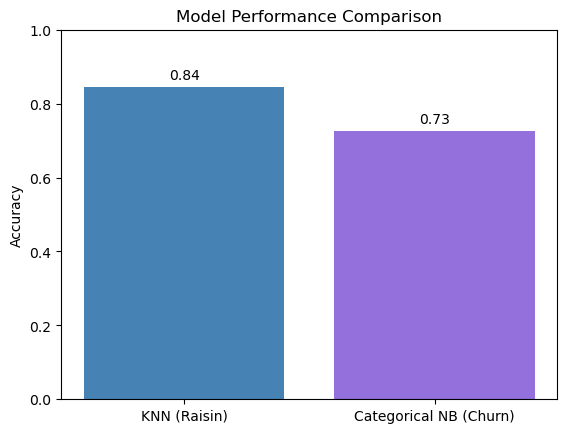

In [60]:
plt.bar(comparison['Model'], comparison['Accuracy'], color=['steelblue', 'mediumpurple'])
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.title('Model Performance Comparison')
for i, acc in enumerate(comparison['Accuracy']):
    plt.text(i, acc + 0.02, f"{acc:.2f}", ha='center')
plt.show()